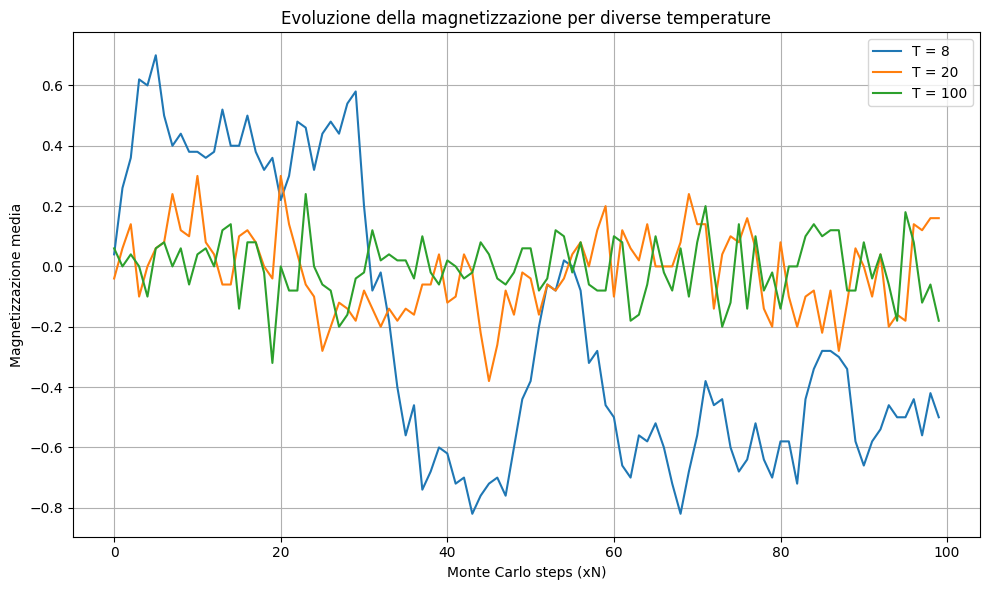

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
N = 100 # Numero di vertici
steps = 10000 # Numero di passi Monte Carlo
temperature = [8, 20, 100] # Temperature da testare

G = nx.erdos_renyi_graph(N, 0.1)

def energia_totale(spins):
  energia = 0
  for i, j in G.edges:
    energia -= spins[i] * spins[j]
  return energia

def delta_energia(i, spins):
  somma_vicini = sum(spins[j] for j in G.neighbors(i))
  return 2 * spins[i] * somma_vicini
plt.figure(figsize=(10, 6))
for T in temperature:
  spins = {i: np.random.choice([-1, 1]) for i in G.nodes}
  magnetizzazione = []
  for step in range(steps):
    i = np.random.choice(list(G.nodes))
    dE = delta_energia(i, spins)
    if dE <= 0 or np.random.rand() < np.exp(-dE / T):
      spins[i] *= -1
    if step % N == 0:
      M = sum(spins.values()) / N
      magnetizzazione.append(M)
  plt.plot(magnetizzazione, label=f"T = {T}")

plt.xlabel("Monte Carlo steps (xN)")
plt.ylabel("Magnetizzazione media")
plt.title("Evoluzione della magnetizzazione per diverse temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("magnetizzazione_confronto.png", dpi=300)
plt.show()